## Regridding TEMPO to 0.1x0.1 grid 

This notebook takes the filtered TEMPO NO2 pixels and averages them into 0.1° × 0.1° grid cell for each TEMPO scan. It gives  one row per grid cell per hour instead of one row per pixel. It also measures of how much the pixels inside each grid cell varied, and drops grid cell built from too few pixels.

In [1]:
import numpy as np
import pandas as pd
import dask.dataframe as dd
import xarray as xr
import xesmf as xe
from pathlib import Path
from tqdm import tqdm

### Read lazily with dask

In [2]:
no2_file = '/global/scratch/users/rubypercival/TEMPO24/parquet_V04/filtered/lowCF_filtered_mar-july_no2_V04.parquet'
no2_ddf = dd.read_parquet(
    no2_file,
    columns=['date', 'time', 'datetime', 'latitude', 'longitude',
             'no2', 'eff_cloud_fraction', 'amf_cloud_fraction', 'snow_ice_fraction'],
    engine='pyarrow')

In [3]:
gridding_ddf = no2_ddf[no2_ddf['no2'] >= 0]

In [4]:
gridding_ddf['grid_lat'] = (np.floor(gridding_ddf['latitude'] * 10) / 10) + 0.05
gridding_ddf['grid_lon'] = (np.floor(gridding_ddf['longitude'] * 10) / 10) + 0.05

gridding_ddf['grid_lat'] = (gridding_ddf['grid_lat'] * 100).round().astype(int) / 100
gridding_ddf['grid_lon'] = (gridding_ddf['grid_lon'] * 100).round().astype(int) / 100

In [5]:
for col in ['no2', 'eff_cloud_fraction', 'amf_cloud_fraction', 'snow_ice_fraction']:
    gridding_ddf[col] = dd.to_numeric(gridding_ddf[col], errors='coerce')

agg_ddf = (
    gridding_ddf.groupby(['datetime', 'grid_lat', 'grid_lon'])
      .agg(
          no2_mean=('no2', 'mean'),
          no2_std=('no2', 'std'),
          no2_count=('no2', 'size'),
          eff_cloud_fraction_mean=('eff_cloud_fraction', 'mean'),
          eff_cloud_fraction_std=('eff_cloud_fraction', 'std'),
          amf_cloud_fraction_mean=('amf_cloud_fraction', 'mean'),
          amf_cloud_fraction_std=('amf_cloud_fraction', 'std'),
          snow_ice_fraction_mean=('snow_ice_fraction', 'mean'),
          snow_ice_fraction_std=('snow_ice_fraction', 'std'),))

In [8]:
agg = agg_ddf.compute().reset_index()
agg['no2_sem'] = agg['no2_std'] / np.sqrt(agg['no2_count'])
agg.loc[agg['no2_count'] <= 1, 'no2_sem'] = np.nan
agg.head()


,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,no2_sem
0,2024-04-28 13:36:38.029074,36.05,-80.55,9.598033e+14,4.405143e+14,25,0.024594,0.003001,0.123984,0.013526,0.0,0.0,8.810287e+13
1,2024-04-28 13:36:38.029074,36.35,-101.65,1.522695e+15,5.267550e+14,25,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.053510e+14
2,2024-04-28 13:36:38.029074,36.55,-89.85,2.440906e+15,NaN,1,0.082857,NaN,0.277283,NaN,0.0,NaN,NaN
3,2024-04-28 13:36:38.029074,36.65,-87.15,1.771678e+15,4.801409e+14,25,0.023199,0.003127,0.103296,0.012250,0.0,0.0,9.602818e+13
4,2024-04-28 13:36:38.029074,36.65,-82.35,1.508406e+15,5.445526e+14,25,0.014841,0.005620,0.077634,0.025346,0.0,0.0,1.089105e+14


In [9]:
agg['cv'] = agg['no2_std'] / agg['no2_mean']


In [10]:
agg


,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,no2_sem,cv
0,2024-04-28 13:36:38.029074,36.05,-80.55,9.598033e+14,4.405143e+14,25,0.024594,0.003001,0.123984,0.013526,0.0,0.0,8.810287e+13,0.458963
1,2024-04-28 13:36:38.029074,36.35,-101.65,1.522695e+15,5.267550e+14,25,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.053510e+14,0.345936
2,2024-04-28 13:36:38.029074,36.55,-89.85,2.440906e+15,NaN,1,0.082857,NaN,0.277283,NaN,0.0,NaN,NaN,NaN
3,2024-04-28 13:36:38.029074,36.65,-87.15,1.771678e+15,4.801409e+14,25,0.023199,0.003127,0.103296,0.012250,0.0,0.0,9.602818e+13,0.271009
4,2024-04-28 13:36:38.029074,36.65,-82.35,1.508406e+15,5.445526e+14,25,0.014841,0.005620,0.077634,0.025346,0.0,0.0,1.089105e+14,0.361012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25842837,2024-06-14 14:40:49.026964,48.25,-101.35,2.231522e+15,9.046172e+14,25,0.005159,0.005767,0.020274,0.022322,0.0,0.0,1.809234e+14,0.405381
25842838,2024-06-14 14:40:49.026964,48.25,-93.15,5.126158e+14,6.263508e+14,16,0.002181,0.003955,0.010286,0.018282,0.0,0.0,1.565877e+14,1.221872
25842839,2024-06-14 14:40:49.026964,48.35,-94.45,1.068936e+15,7.929801e+14,15,0.024599,0.011901,0.101435,0.045092,0.0,0.0,2.047466e+14,0.741841
25842840,2024-06-14 14:40:49.026964,48.45,-99.45,1.285680e+15,6.510088e+14,25,0.008919,0.003305,0.036196,0.012992,0.0,0.0,1.302018e+14,0.506354


In [11]:
agg['cv'].describe()


count    2.541599e+07
mean     4.175567e-01
std      2.008757e-01
min      0.000000e+00
25%      2.760854e-01
50%      3.971795e-01
75%      5.361105e-01
max      2.418494e+00
Name: cv, dtype: float64

/global/home/users/rubypercival/.conda/envs/smap/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


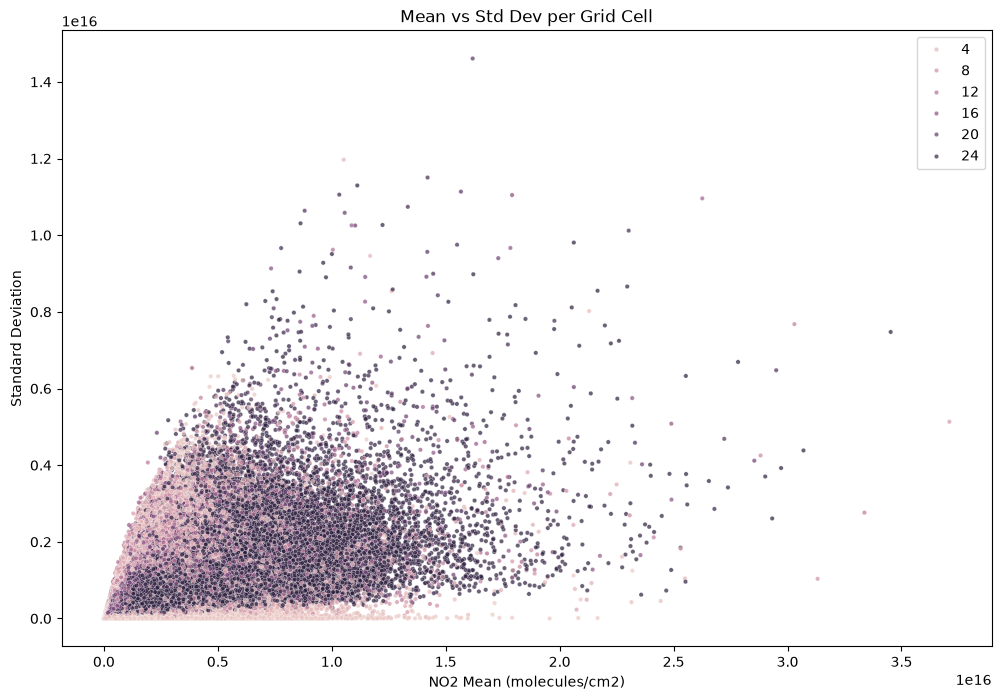

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,8))
sns.scatterplot(data=agg, x='no2_mean', y='no2_std', hue='no2_count', s=10, alpha=0.7)
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.ylabel('Standard Deviation')
plt.legend()
plt.title('Mean vs Std Dev per Grid Cell')
plt.show()


each dot is one (hour, 0.1° grid cell) combination, and the color shows how many raw TEMPO pixels went into that cell's average

Standard deviation generally grows as the mean NO2 value increases, can see the cloud of points widening as you move right along the x-axis

places/times with higher NO2 concentrations (likely urban or industrial areas, or plume events) also tend to have more variable NO2 within that 0.1° cell

darker points (higher pixel counts, 20-24) cluster into a denser, lower-std band, while the lighter points (lower counts, 4) are scattered more broadly 

this plot is the visual justification for the filtering step that comes right after it

filtered_df = agg[agg['no2_count'] >= 13]

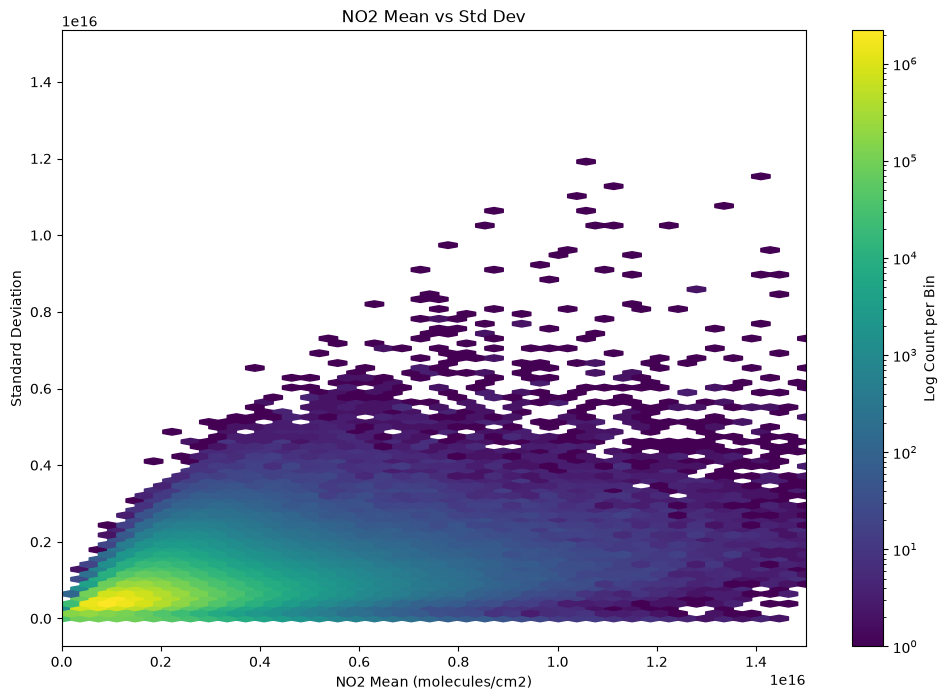

In [15]:
plt.figure(figsize=(12, 8))
hb = plt.hexbin(agg['no2_mean'], agg['no2_std'], gridsize=100, cmap='viridis', bins='log')
plt.colorbar(hb, label='Log Count per Bin')
plt.xlabel('NO2 Mean (molecules/cm2)')
plt.xlim(0, 1.5e16)
plt.ylabel('Standard Deviation')
plt.title('NO2 Mean vs Std Dev')
plt.show()


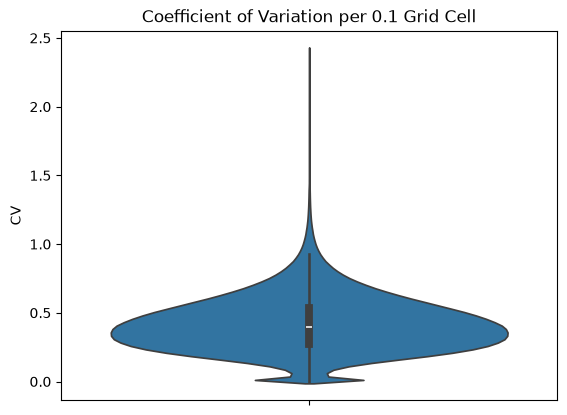

In [16]:
sns.violinplot(data=agg, y='cv', inner='box')
plt.title('Coefficient of Variation per 0.1 Grid Cell')
plt.ylabel('CV')
plt.show()


The bulk of the data sits in a fairly tight range -> the widest part of the violin, roughly CV = 0.3 to 0.5, with the median around 0.4. 

There's a long, thin tail stretching up to about CV ≈ 2.5. This is a small number of grid-cell-hours where the standard deviation was larger than the mean itself (CV > 1) meaning the raw pixels within that cell were wildly inconsistent relative to their average. 

There's a second, smaller bulge right near CV = 0, a cluster of grid-cell-hours with very low variability (pixels within the cell were nearly identical). 

if a grid cell's average came from only 1-2 pixels, std can end up very small or exactly zero just because there's barely any spread possible with so few values, not because the underlying air was genuinely uniform.

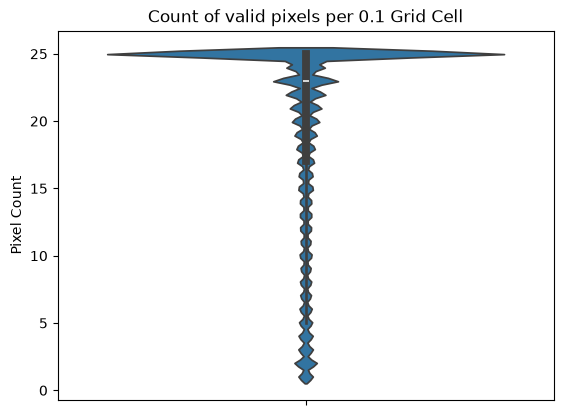

In [17]:
sns.violinplot(data=agg, y='no2_count', inner='box')
plt.title('Count of valid pixels per 0.1 Grid Cell')
plt.ylabel('Pixel Count')
plt.show()


In [18]:
filtered_df = agg[agg['no2_count'] >= 13].copy()

In [19]:
filtered_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,no2_sem,cv
0,2024-04-28 13:36:38.029074,36.05,-80.55,9.598033e+14,4.405143e+14,25,0.024594,0.003001,0.123984,0.013526,0.0,0.0,8.810287e+13,0.458963
1,2024-04-28 13:36:38.029074,36.35,-101.65,1.522695e+15,5.267550e+14,25,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.053510e+14,0.345936
3,2024-04-28 13:36:38.029074,36.65,-87.15,1.771678e+15,4.801409e+14,25,0.023199,0.003127,0.103296,0.012250,0.0,0.0,9.602818e+13,0.271009
4,2024-04-28 13:36:38.029074,36.65,-82.35,1.508406e+15,5.445526e+14,25,0.014841,0.005620,0.077634,0.025346,0.0,0.0,1.089105e+14,0.361012
5,2024-04-28 13:36:38.029074,36.75,-102.85,9.376960e+14,3.519136e+14,25,0.000000,0.000000,0.000000,0.000000,0.0,0.0,7.038271e+13,0.375296
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25842837,2024-06-14 14:40:49.026964,48.25,-101.35,2.231522e+15,9.046172e+14,25,0.005159,0.005767,0.020274,0.022322,0.0,0.0,1.809234e+14,0.405381
25842838,2024-06-14 14:40:49.026964,48.25,-93.15,5.126158e+14,6.263508e+14,16,0.002181,0.003955,0.010286,0.018282,0.0,0.0,1.565877e+14,1.221872
25842839,2024-06-14 14:40:49.026964,48.35,-94.45,1.068936e+15,7.929801e+14,15,0.024599,0.011901,0.101435,0.045092,0.0,0.0,2.047466e+14,0.741841
25842840,2024-06-14 14:40:49.026964,48.45,-99.45,1.285680e+15,6.510088e+14,25,0.008919,0.003305,0.036196,0.012992,0.0,0.0,1.302018e+14,0.506354


In [21]:
filtered_df = filtered_df.rename(columns={'cv':'cv_no2'})

In [22]:
output_dir = Path('/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets')
output_dir.mkdir(parents=True, exist_ok=True)
output_parquet = output_dir / 'lowCF_TEMPO_0.1x0.1_gridded_mar-jul24_V04.parquet'
filtered_df.to_parquet(output_parquet, engine='pyarrow')
print('Saved to:', output_parquet)

Saved to: /global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/lowCF_TEMPO_0.1x0.1_gridded_mar-jul24_V04.parquet
